# Backtest results: HMM regime signals

**Setup (both runs)**
- Data: S&P 500 index price; features price-only (windows 5/10/60, half-lives 5/10/60)
- Pipeline: standardize → 95% PCA, 2 states, seed 0
- Refit (scaler, PCA, model) every 63 decisions; 3 warm-start steps in between
- Signal: next-day bull probability ≥ 0.5 → 12-day median → next-day return; no costs
- Only PCA branches; MA 50/200 is the benchmark

**Run A: 2004-01-02 → 2025-12-30** (10-year start window, 5,534 decisions)
- **Gaussian**, **Student-t**: full covariance, EM (`run_backtest.py`)
  - Student-t df: one per state, learned in the EM M-step (start 10, range 2.1–200)
- **GMM (M=2)**, **GMM (M=3)**: full covariance, EM
- **Flow**: spline flow, Student-t base with fixed df = 5, 1 layer, 8 bins, EM (`--engine flow`)
  - M-step: 5 Adam updates per state per EM iteration (batch 2048, lr 1e-3)
  - Refit: up to 100 EM iterations → at most 500 updates per state (1,000 total); stops early on convergence
  - Warm-start day: 3 EM iterations → 15 updates per state (30 total)
- **Flow (normal)**: same flow, standard normal base (`--engine flow --base normal`)

**Run B: 2004-01-02 → 2013-12-31** (5-year start window)
- **GMM (M=2…5)**: full covariance, EM; component sweep

One seed, one path: results are descriptive.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook inside the project")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks" / "sp500"))
from backtest_experiment import evaluate_signals
from model_evaluation.market_strategy.evaluation import compare_strategies
from model_evaluation.market_strategy.strategies import moving_average_timing

RESULTS = ROOT / "notebooks/sp500/results"
prices = pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                     parse_dates=["YYYYMMDD"]).set_index("YYYYMMDD")["DlyPrcInd"]


def load(*folders):
    """Load PCA signals from result folders, keeping only common dates."""
    frames = []
    for folder in folders:
        path = RESULTS / folder / "signals.csv"
        if not path.exists():
            raise FileNotFoundError(f"Missing {path}")
        frame = pd.read_csv(path, parse_dates=["date"])
        frames.append(frame.loc[frame["pca"].eq(True)])
    common = set.intersection(*(set(f.date) for f in frames))
    fits = pd.concat([f.loc[f.date.isin(common)] for f in frames],
                     ignore_index=True)
    assert not fits.duplicated(["date", "spec"]).any()
    gmm = fits["model"].eq("GMM")
    fits.loc[gmm, "model"] = "GMM (M=" + fits.loc[gmm, "gmm_components"].astype(str) + ")"
    print(f"{fits.date.min().date()} → {fits.date.max().date()}, "
          f"{fits.date.nunique()} decisions, {fits.spec.nunique()} models, "
          f"{fits.loc[fits.refresh, 'date'].nunique()} refits")
    return fits


def analyze(fits):
    """Show the strategy table, growth plot and switching table."""
    pnl, weights = evaluate_signals(fits, prices, median_window=12)
    decision_dates = pd.DatetimeIndex(fits.date.drop_duplicates().sort_values())
    next_dates = prices.index[prices.index.get_indexer(decision_dates) + 1]
    # moving_average_timing shifts internally: today's close sets tomorrow's position.
    ma_weights = moving_average_timing(prices, fast=50, slow=200).reindex(next_dates)
    ma_weights.index = decision_dates
    ma_returns = prices.pct_change(fill_method=None).reindex(next_dates)
    pnl["MA 50/200"] = pd.Series(np.log1p(ma_weights.to_numpy() * ma_returns.to_numpy()),
                                 index=ma_weights.index)
    weights["MA 50/200"] = ma_weights
    summary = compare_strategies(pnl, weights)
    for name in summary.index:
        switches = int(np.count_nonzero(np.diff(weights[name].sort_index().to_numpy())))
        summary.loc[name, "total_switches"] = switches
        summary.loc[name, "avg_persistent_days"] = len(weights[name]) / (switches + 1)
    summary["total_switches"] = summary["total_switches"].astype(int)
    display(summary[["total_return", "sharpe", "max_drawdown", "exposure",
                     "turnover_per_year", "total_switches",
                     "avg_persistent_days"]].round(3))
    fig, ax = plt.subplots(figsize=(11, 4))
    for name, series in pnl.items():
        ax.plot(series.index, np.exp(series.cumsum()), label=name, linewidth=1.1)
    ax.set(ylabel="Growth of $1", title="HMM strategies")
    ax.legend(ncol=2, fontsize=8)
    fig.tight_layout()
    plt.show()
    years = fits.date.nunique() / 252
    rows = []
    for (name, pca), group in fits.groupby(["model", "pca"]):
        raw = group.sort_values("date").bull_raw.to_numpy()
        held = np.count_nonzero(np.diff(weights[f"{name} / PCA"].to_numpy()))
        rows.append({"model": f"{name} / PCA",
                     "raw switches/year": np.count_nonzero(np.diff(raw)) / years,
                     "median switches/year": held / years})
    display(pd.DataFrame(rows).set_index("model").round(2))
    return pnl, weights

## Run A: 2004–2025, all models

2004-01-02 → 2025-12-30, 5534 decisions, 6 models, 88 refits


,total_return,sharpe,max_drawdown,exposure,turnover_per_year,total_switches,avg_persistent_days
Student-t / PCA,2.517,0.640,-0.214,0.456,5.009,110,49.856
GMM (M=3) / PCA,3.796,0.544,-0.339,0.557,4.463,98,55.899
MA 50/200,3.329,0.494,-0.339,0.776,1.002,22,240.609
Flow / PCA,3.009,0.490,-0.305,0.555,3.871,85,64.349
Buy and hold,5.176,0.439,-0.568,1.000,0.000,0,5534.000
GMM (M=2) / PCA,1.386,0.356,-0.292,0.367,4.872,107,51.241
Flow (normal) / PCA,1.649,0.340,-0.285,0.502,4.918,108,50.771
Gaussian / PCA,0.606,0.243,-0.239,0.196,3.324,73,74.784


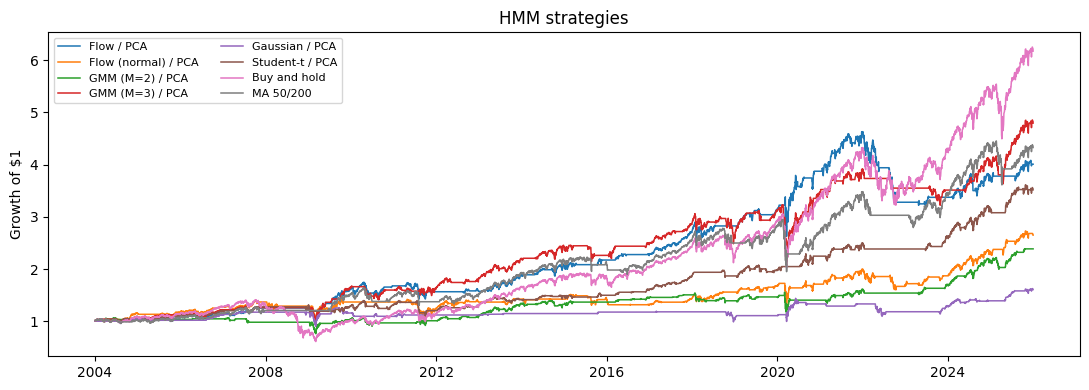

,raw switches/year,median switches/year
model,,
Flow / PCA,9.11,3.87
Flow (normal) / PCA,11.84,4.92
GMM (M=2) / PCA,9.70,4.87
GMM (M=3) / PCA,9.38,4.46
Gaussian / PCA,9.88,3.32
Student-t / PCA,6.56,5.01


In [2]:
fits_a = load("merged_regime_2004_2025", "flow_2004_2025",
              "flow_normal_2004_2025")
pnl_a, weights_a = analyze(fits_a)

## Run A: agreement with Flow (raw bull decision)

,agreement with flow_pca
spec,
flow_normal,0.715
gaussian_pca,0.501
gmm2_pca,0.571
gmm3_pca,0.630
student_t_pca,0.651


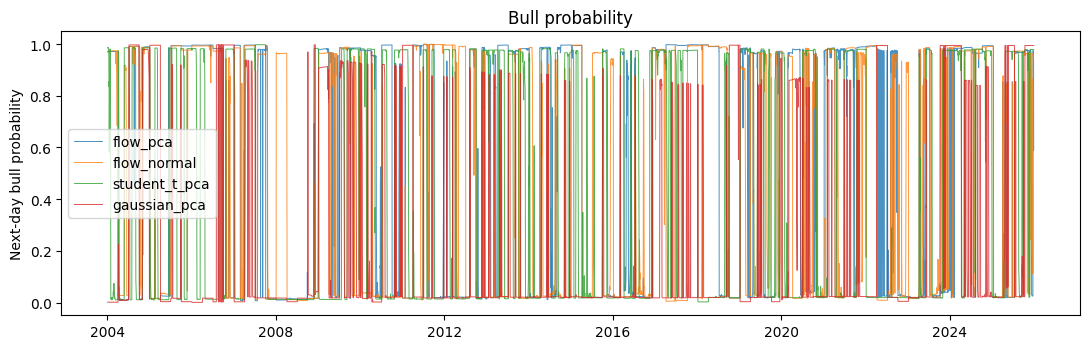

In [3]:
raw = fits_a.pivot(index="date", columns="spec", values="bull_raw")
agreement = raw.drop(columns="flow_pca").eq(raw["flow_pca"], axis=0).mean()
display(agreement.rename("agreement with flow_pca").round(3).to_frame())
probability = fits_a.pivot(index="date", columns="spec", values="bull_probability")
fig, ax = plt.subplots(figsize=(11, 3.6))
for spec in ("flow_pca", "flow_normal", "student_t_pca", "gaussian_pca"):
    ax.plot(probability.index, probability[spec], linewidth=0.7, alpha=0.8, label=spec)
ax.set(ylabel="Next-day bull probability", title="Bull probability")
ax.legend()
fig.tight_layout()
plt.show()

## Run A: learned Student-t df at the last refit

In [4]:
import pickle
import backtest_experiment

# The classic run was pickled under the module's old name.
sys.modules.setdefault("paper_regime_experiment", backtest_experiment)


def read_checkpoint(folder):
    """Load a trusted checkpoint written by this project's backtest scripts."""
    with (RESULTS / folder / "checkpoint.pkl").open("rb") as handle:
        return pickle.load(handle)


classic = read_checkpoint("paper_regime_2004_2025")
classic_dof = classic["branches"][("Student-t", True)][0].emission.dof
rows = [{"model": "Student-t / PCA", "state": k, "df": nu, "how": "learned (EM)"}
        for k, nu in enumerate(classic_dof)]
rows += [{"model": "Flow / PCA", "state": "both", "df": 5.0, "how": "fixed base"}]
display(pd.DataFrame(rows).set_index(["model", "state"]).round(2))

df           how
model           state                    
Student-t / PCA 0      2.10  learned (EM)
                1      2.13  learned (EM)
Flow / PCA      both   5.00    fixed base

## Run B: 2004–2013, GMM component sweep

2004-01-02 → 2013-12-31, 2517 decisions, 4 models, 40 refits


,total_return,sharpe,max_drawdown,exposure,turnover_per_year,total_switches,avg_persistent_days
MA 50/200,0.917,0.541,-0.205,0.735,1.001,10,228.818
GMM (M=3) / PCA,0.842,0.507,-0.208,0.578,5.406,54,45.764
GMM (M=2) / PCA,0.530,0.277,-0.319,0.593,5.406,54,45.764
Buy and hold,0.653,0.246,-0.568,1.000,0.000,0,2517.000
GMM (M=5) / PCA,0.227,0.191,-0.211,0.416,4.906,49,50.340
GMM (M=4) / PCA,0.179,0.110,-0.336,0.570,4.605,46,53.553


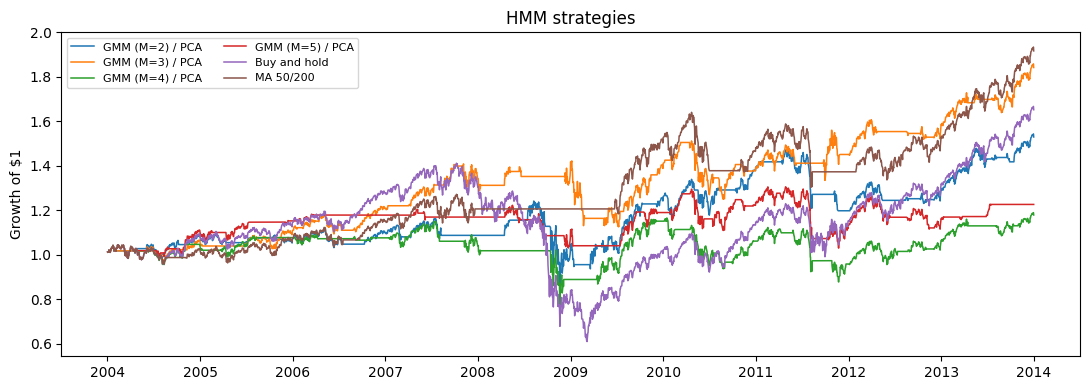

,raw switches/year,median switches/year
model,,
GMM (M=2) / PCA,11.01,5.41
GMM (M=3) / PCA,11.61,5.41
GMM (M=4) / PCA,12.21,4.61
GMM (M=5) / PCA,11.41,4.91


In [5]:
fits_b = load("gmm_sweep_2004_2013")
pnl_b, weights_b = analyze(fits_b)